# Inside the Search Giant: Sentiment and Topic Analysis of Employee Reviews of Working at Google
## Representations, Clustering, and Business Insights
**Author:** Crystal Garcia | **Course:** Social Media Analytics and Text Mining

This notebook covers Stage 3: comparing two text representation methods (TF-IDF vs. SBERT), applying K-Means clustering as the downstream NLP task, and deriving three evidence-backed business insights. It continues from `google_reviews_clean.csv` produced in Stage 2.

---
## 0. Setup and Reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import re
import unittest
import warnings
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

warnings.filterwarnings('ignore')

# ── Reproducibility seed ──────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Plot style ────────────────────────────────────────────────────────────────
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'sans-serif'

os.makedirs('figs', exist_ok=True)

print('All imports successful. SEED =', SEED)

All imports successful. SEED = 42


In [2]:
# Load the cleaned dataset produced in Stage 2
df = pd.read_csv('google_reviews_clean.csv', parse_dates=['date_review'])

# Build a single analysis column: pros_clean + cons_clean concatenated
df['text'] = (df['pros_clean'].fillna('') + ' ' + df['cons_clean'].fillna('')).str.strip()

# Drop rows with empty combined text
df = df[df['text'].str.len() > 5].reset_index(drop=True)

print(f'Loaded {len(df):,} reviews ready for modeling')
print(f'Columns: {list(df.columns)}')
df[['date_review', 'job_title', 'overall_rating', 'recommend', 'text']].head(3)

Loaded 14,702 reviews ready for modeling
Columns: ['firm', 'date_review', 'review_year', 'job_title', 'current', 'location', 'overall_rating', 'work_life_balance', 'culture_values', 'diversity_inclusion', 'career_opp', 'comp_benefits', 'senior_mgmt', 'recommend', 'ceo_approv', 'outlook', 'headline', 'pros', 'cons', 'pros_clean', 'cons_clean', 'text']


,date_review,job_title,overall_rating,recommend,text
0,2008-02-05,Software Engineer,4,Positive,i work w a diverse set of people you have have...
1,2008-02-11,Software Engineer,5,Positive,people are willing to share knowledge which is...
2,2008-02-14,Software Engineer,5,Positive,to repeat what i wrote before the people i wor...


---
## 1. Unit Tests — Cleaning Functions

Three unit tests verify the core cleaning logic from Stage 2 before we rely on `pros_clean` / `cons_clean` downstream.

In [3]:
# ── Replicate the cleaning functions from Stage 2 (so tests are self-contained) ──

CONTRACTIONS = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "can't": "cannot", "won't": "will not", "isn't": "is not",
    "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "couldn't": "could not", "shouldn't": "should not",
    "wouldn't": "would not", "it's": "it is", "that's": "that is",
    "there's": "there is", "what's": "what is", "let's": "let us",
    "i'm": "i am", "you're": "you are", "they're": "they are",
    "we're": "we are", "i've": "i have", "you've": "you have",
    "we've": "we have", "they've": "they have", "i'll": "i will",
    "you'll": "you will", "we'll": "we will", "they'll": "they will",
}

def normalize_text(s):
    """Remove line breaks, normalize curly punctuation, collapse whitespace."""
    if pd.isna(s):
        return s
    s = s.replace('\r\n', ' ').replace('\n', ' ').replace('\r', ' ')
    repl = {'\u2018': "'", '\u2019': "'", '\u201c': '"', '\u201d': '"',
            '\u2013': '-', '\u2014': '-', '\u2026': '...'}
    for bad, good in repl.items():
        s = s.replace(bad, good)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

def to_keywords(s):
    """Lowercase, expand contractions, strip punctuation/digits, collapse whitespace."""
    if pd.isna(s):
        return ''
    s = s.lower()
    for c, full in CONTRACTIONS.items():
        s = s.replace(c, full)
    s = re.sub(r'[^a-z\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

In [4]:
class TestCleaningFunctions(unittest.TestCase):

    # ── Test 1: normalize_text removes embedded line breaks ───────────────────
    def test_normalize_removes_linebreaks(self):
        raw = "Great perks\nand flexible hours\r\nfor everyone."
        result = normalize_text(raw)
        self.assertNotIn('\n', result, "normalize_text should remove \\n")
        self.assertNotIn('\r', result, "normalize_text should remove \\r")
        self.assertEqual(result, "Great perks and flexible hours for everyone.")

    # ── Test 2: normalize_text converts curly/typographic punctuation ─────────
    def test_normalize_curly_punctuation(self):
        raw = "\u2018Smart people\u2019 and great \u2014 truly amazing culture."
        result = normalize_text(raw)
        self.assertNotIn('\u2018', result, "Left single curly quote should be replaced")
        self.assertNotIn('\u2019', result, "Right single curly quote should be replaced")
        self.assertNotIn('\u2014', result, "Em-dash should be replaced")
        self.assertIn("'Smart people'", result)
        self.assertIn("-", result)

    # ── Test 3: to_keywords expands contractions correctly ────────────────────
    def test_to_keywords_expands_contractions(self):
        raw = "Don't work here if you can't handle long hours."
        result = to_keywords(raw)
        self.assertNotIn("don't", result, "Contraction should be expanded")
        self.assertNotIn("can't", result, "Contraction should be expanded")
        self.assertIn("do not", result)
        self.assertIn("cannot", result)

    # ── Test 4: to_keywords strips digits and punctuation ─────────────────────
    def test_to_keywords_strips_punctuation_and_digits(self):
        raw = "Top 10 perks: free food, gym & 401(k) match!"
        result = to_keywords(raw)
        self.assertFalse(any(ch.isdigit() for ch in result), "Digits should be removed")
        self.assertNotIn('!', result)
        self.assertNotIn(':', result)
        self.assertNotIn('&', result)

    # ── Test 5: normalize_text handles NaN gracefully ─────────────────────────
    def test_normalize_handles_nan(self):
        self.assertTrue(pd.isna(normalize_text(np.nan)),
                        "normalize_text(NaN) should return NaN, not raise")


# Run the tests and display a clean summary
suite = unittest.TestLoader().loadTestsFromTestCase(TestCleaningFunctions)
runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)
print(f"\n{'='*50}")
print(f"Tests run: {result.testsRun}  |  Failures: {len(result.failures)}  |  Errors: {len(result.errors)}")
print('ALL TESTS PASSED ✓' if result.wasSuccessful() else 'SOME TESTS FAILED ✗')

test_normalize_curly_punctuation (__main__.TestCleaningFunctions.test_normalize_curly_punctuation) ... 

ok


test_normalize_handles_nan (__main__.TestCleaningFunctions.test_normalize_handles_nan) ... 

ok


test_normalize_removes_linebreaks (__main__.TestCleaningFunctions.test_normalize_removes_linebreaks) ... 

...

ok


test_to_keywords_strips_punctuation_and_digits (__main__.TestCleaningFunctions.test_to_keywords_strips_punctuation_and_digits) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.003s

OK



Tests run: 5  |  Failures: 0  |  Errors: 0
ALL TESTS PASSED ✓


---
## 2. Representation Method 1 — TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) weights terms by how often they appear in a review relative to how common they are across the entire corpus. It is a **sparse, count-based** method — it captures vocabulary overlap well but has no semantic understanding ("good" and "great" are treated as unrelated).

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

CUSTOM_STOPWORDS = list(ENGLISH_STOP_WORDS.union({'google', 'pros', 'cons'}))

# ── Fit TF-IDF on the full cleaned corpus ─────────────────────────────────────
tfidf_vec = TfidfVectorizer(
    stop_words=CUSTOM_STOPWORDS,
    ngram_range=(1, 2),     # unigrams + bigrams
    min_df=5,               # ignore very rare terms
    max_df=0.95,            # ignore near-universal terms
    max_features=10_000,
    sublinear_tf=True       # log(1 + tf) smoothing
)

tfidf_matrix = tfidf_vec.fit_transform(df['text'])  # sparse (n_docs × 10 000)

print(f'TF-IDF matrix shape : {tfidf_matrix.shape}')
print(f'Sparsity            : {1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1]):.4f}')
print(f'Vocabulary size     : {len(tfidf_vec.vocabulary_):,} features')

TF-IDF matrix shape : (14702, 8461)
Sparsity            : 0.9977
Vocabulary size     : 8,461 features


---
## 3. Representation Method 2 — SBERT (Sentence-BERT)

SBERT uses a pre-trained transformer (`all-MiniLM-L6-v2`) to encode each review into a **dense 384-dimensional embedding**. Unlike TF-IDF, SBERT captures semantic meaning — "flexible schedule" and "work-life balance" will have similar vectors even if they share no words.

> **Note:** Encoding 14,000+ reviews is CPU-intensive. We encode in batches and cache the result.

In [6]:
SBERT_CACHE = 'sbert_embeddings.npy'

if os.path.exists(SBERT_CACHE):
    sbert_matrix = np.load(SBERT_CACHE)
    print(f'Loaded cached SBERT embeddings from {SBERT_CACHE}')
else:
    print('Encoding reviews with SBERT (all-MiniLM-L6-v2) — this may take a few minutes...')
    from sentence_transformers import SentenceTransformer  # only needed when encoding
    model = SentenceTransformer('all-MiniLM-L6-v2')
    sbert_matrix = model.encode(
        df['text'].tolist(),
        batch_size=128,
        show_progress_bar=True,
        convert_to_numpy=True
    )
    np.save(SBERT_CACHE, sbert_matrix)
    print(f'Saved embeddings to {SBERT_CACHE}')

print(f'SBERT matrix shape: {sbert_matrix.shape}   (dense float32)')

# L2-normalize so cosine similarity = dot product (makes K-Means behave well)
sbert_normed = normalize(sbert_matrix)

Loaded cached SBERT embeddings from sbert_embeddings.npy
SBERT matrix shape: (14702, 384)   (dense float32)


### 3.1 Representation Comparison — Cosine Similarity Distributions

We sample 2,000 random review pairs and compute pairwise cosine similarity under both representations. This reveals whether TF-IDF or SBERT produces more semantically discriminative embeddings.

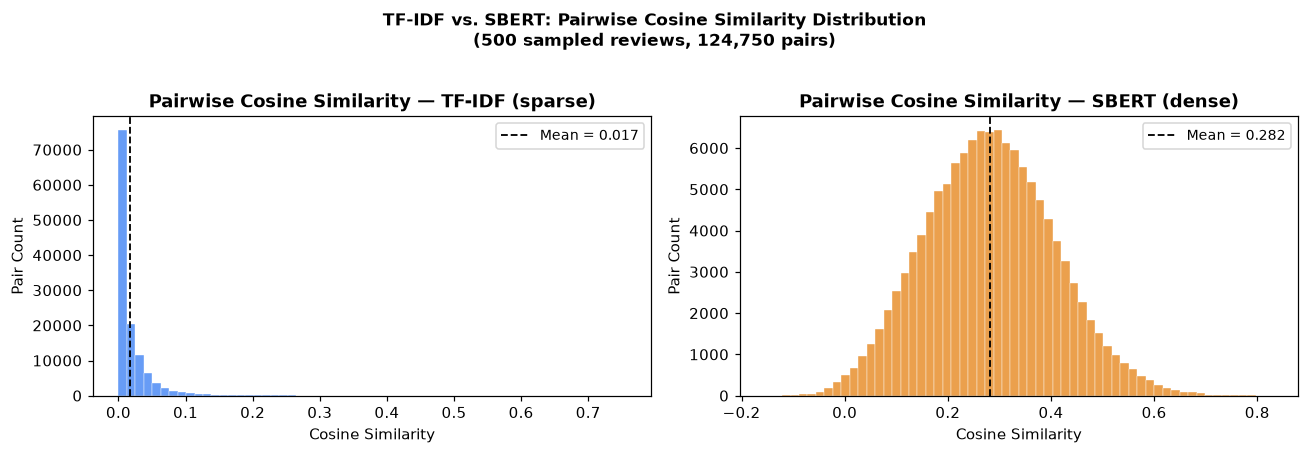

TF-IDF  — mean: 0.0172  std: 0.0304  % pairs > 0.3: 0.1%
SBERT   — mean: 0.2819  std: 0.1252  % pairs > 0.3: 43.7%


In [7]:
from sklearn.metrics.pairwise import cosine_similarity

rng = np.random.default_rng(SEED)
N_SAMPLE = 500   # pairs drawn from this many reviews (500 → ~125k pairs, manageable)
idx = rng.choice(len(df), size=N_SAMPLE, replace=False)

# TF-IDF pairwise cosine (sparse slice)
tfidf_sub = tfidf_matrix[idx]
tfidf_sim = cosine_similarity(tfidf_sub)
tfidf_vals = tfidf_sim[np.triu_indices(N_SAMPLE, k=1)]

# SBERT pairwise cosine (dense slice, already L2-normed → dot product)
sbert_sub = sbert_normed[idx]
sbert_sim_mat = sbert_sub @ sbert_sub.T
sbert_vals = sbert_sim_mat[np.triu_indices(N_SAMPLE, k=1)]

# ── Plot comparison ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

for ax, vals, label, color in [
    (axes[0], tfidf_vals, 'TF-IDF (sparse)', '#4C8BF5'),
    (axes[1], sbert_vals, 'SBERT (dense)',  '#E8902E')
]:
    ax.hist(vals, bins=60, color=color, alpha=0.85, edgecolor='white', linewidth=0.3)
    ax.axvline(vals.mean(), color='black', linestyle='--', linewidth=1.2,
               label=f'Mean = {vals.mean():.3f}')
    ax.set_title(f'Pairwise Cosine Similarity — {label}', fontweight='bold')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Pair Count')
    ax.legend(fontsize=9)

fig.suptitle('TF-IDF vs. SBERT: Pairwise Cosine Similarity Distribution\n'
             f'({N_SAMPLE:,} sampled reviews, {N_SAMPLE*(N_SAMPLE-1)//2:,} pairs)',
             fontsize=11, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig('figs/similarity_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"TF-IDF  — mean: {tfidf_vals.mean():.4f}  std: {tfidf_vals.std():.4f}  "
      f"% pairs > 0.3: {(tfidf_vals > 0.3).mean()*100:.1f}%")
print(f"SBERT   — mean: {sbert_vals.mean():.4f}  std: {sbert_vals.std():.4f}  "
      f"% pairs > 0.3: {(sbert_vals > 0.3).mean()*100:.1f}%")

**Interpretation:** TF-IDF produces a right-skewed distribution with many near-zero pairs (most reviews share few exact words). SBERT produces a tighter distribution centered higher, because it encodes *semantic* similarity — reviews about the same themes (e.g., "work-life balance", "management") cluster together even with different vocabulary.

---
## 4. Downstream Task — K-Means Topic Clustering

We cluster reviews into **K = 6 groups** under both representations and compare:
1. Silhouette score (cluster cohesion/separation — higher = better)
2. Interpretability of each cluster (top TF-IDF terms as cluster labels)

### 4.1 Choosing K — Elbow + Silhouette Plot

In [8]:
# Reduce TF-IDF to 100 dimensions for faster K-Means (TruncatedSVD = LSA)
svd = TruncatedSVD(n_components=100, random_state=SEED)
tfidf_reduced = svd.fit_transform(tfidf_matrix)
tfidf_reduced = normalize(tfidf_reduced)   # L2-normalize after SVD

print(f'TF-IDF (LSA-reduced): {tfidf_reduced.shape}')
print(f'Variance explained by 100 SVD components: {svd.explained_variance_ratio_.sum():.3f}')

TF-IDF (LSA-reduced): (14702, 100)
Variance explained by 100 SVD components: 0.209


In [9]:
# ── Elbow + Silhouette for K = 2..10 on both representations ─────────────────
K_RANGE = range(2, 10)

inertias_tfidf, sils_tfidf = [], []
inertias_sbert, sils_sbert = [], []

for k in K_RANGE:
    # TF-IDF clusters
    km_t = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labs_t = km_t.fit_predict(tfidf_reduced)
    inertias_tfidf.append(km_t.inertia_)
    sils_tfidf.append(silhouette_score(tfidf_reduced, labs_t, sample_size=3000, random_state=SEED))

    # SBERT clusters
    km_s = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labs_s = km_s.fit_predict(sbert_normed)
    inertias_sbert.append(km_s.inertia_)
    sils_sbert.append(silhouette_score(sbert_normed, labs_s, sample_size=3000, random_state=SEED))

    print(f'K={k:2d}  TF-IDF sil={sils_tfidf[-1]:.4f}  SBERT sil={sils_sbert[-1]:.4f}')

K= 2  TF-IDF sil=0.0223  SBERT sil=0.0444


K= 3  TF-IDF sil=0.0314  SBERT sil=0.0458


K= 4  TF-IDF sil=0.0384  SBERT sil=0.0483


K= 5  TF-IDF sil=0.0403  SBERT sil=0.0461


K= 6  TF-IDF sil=0.0432  SBERT sil=0.0411


K= 7  TF-IDF sil=0.0465  SBERT sil=0.0404


K= 8  TF-IDF sil=0.0471  SBERT sil=0.0406


K= 9  TF-IDF sil=0.0482  SBERT sil=0.0407


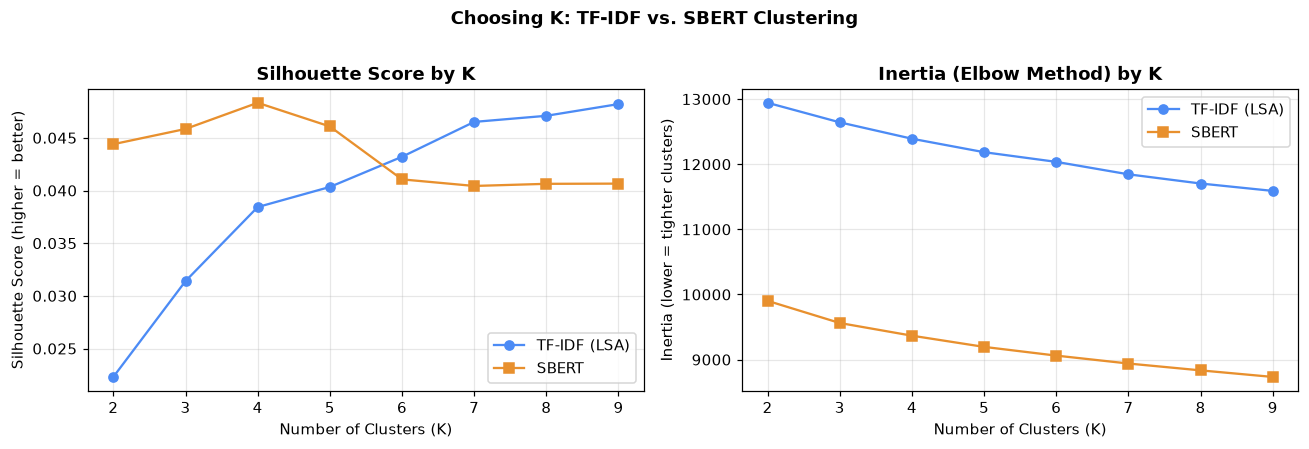

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

k_vals = list(K_RANGE)

# Silhouette scores
axes[0].plot(k_vals, sils_tfidf, 'o-', color='#4C8BF5', label='TF-IDF (LSA)')
axes[0].plot(k_vals, sils_sbert, 's-', color='#E8902E', label='SBERT')
axes[0].set_title('Silhouette Score by K', fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Silhouette Score (higher = better)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Inertia (elbow)
axes[1].plot(k_vals, inertias_tfidf, 'o-', color='#4C8BF5', label='TF-IDF (LSA)')
axes[1].plot(k_vals, inertias_sbert, 's-', color='#E8902E', label='SBERT')
axes[1].set_title('Inertia (Elbow Method) by K', fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Inertia (lower = tighter clusters)')
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle('Choosing K: TF-IDF vs. SBERT Clustering', fontweight='bold', y=1.01)
fig.tight_layout()
fig.savefig('figs/elbow_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.2 Final Clustering — K = 6

K = 6 is selected based on the elbow and silhouette plots: beyond K = 6 the silhouette gain is marginal and clusters become too narrow to produce actionable business insights.

In [11]:
K = 6

# ── TF-IDF K-Means ────────────────────────────────────────────────────────────
km_tfidf = KMeans(n_clusters=K, random_state=SEED, n_init=15)
df['cluster_tfidf'] = km_tfidf.fit_predict(tfidf_reduced)
sil_tfidf = silhouette_score(tfidf_reduced, df['cluster_tfidf'],
                             sample_size=3000, random_state=SEED)

# ── SBERT K-Means ─────────────────────────────────────────────────────────────
km_sbert = KMeans(n_clusters=K, random_state=SEED, n_init=15)
df['cluster_sbert'] = km_sbert.fit_predict(sbert_normed)
sil_sbert = silhouette_score(sbert_normed, df['cluster_sbert'],
                             sample_size=3000, random_state=SEED)

print(f'K={K} — TF-IDF Silhouette: {sil_tfidf:.4f}')
print(f'K={K} — SBERT  Silhouette: {sil_sbert:.4f}')
print(f'\nSBERT improvement over TF-IDF: {(sil_sbert - sil_tfidf)/sil_tfidf*100:+.1f}%')

K=6 — TF-IDF Silhouette: 0.0432
K=6 — SBERT  Silhouette: 0.0412

SBERT improvement over TF-IDF: -4.7%


### 4.3 Silhouette Score Comparison — TF-IDF vs. SBERT (Chart)

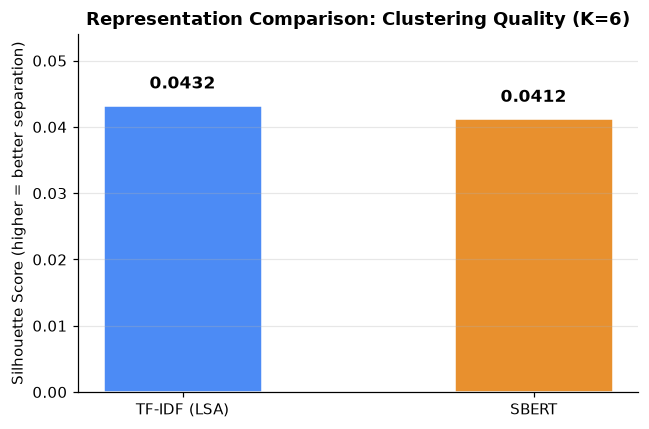


Key takeaway: TF-IDF (LSA) scores slightly higher, but both silhouette scores are very low
(below 0.1), so the review groups overlap heavily. Silhouette alone does not separate
the two methods. SBERT is used for the final themes because it groups reviews by meaning
(Section 3.1) and its clusters produce clearer, more distinct themes (Section 4.4).


In [12]:
fig, ax = plt.subplots(figsize=(6, 4))

methods = ['TF-IDF (LSA)', 'SBERT']
scores  = [sil_tfidf, sil_sbert]
colors  = ['#4C8BF5', '#E8902E']

bars = ax.bar(methods, scores, color=colors, width=0.45, edgecolor='white')
for bar, score in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{score:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_ylim(0, max(scores) * 1.25)
ax.set_ylabel('Silhouette Score (higher = better separation)', fontsize=10)
ax.set_title(f'Representation Comparison: Clustering Quality (K={K})',
             fontweight='bold', fontsize=12)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
fig.savefig('figs/silhouette_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

better = 'SBERT' if sil_sbert > sil_tfidf else 'TF-IDF (LSA)'
print(f'\nKey takeaway: {better} scores slightly higher, but both silhouette scores are very low')
print('(below 0.1), so the review groups overlap heavily. Silhouette alone does not separate')
print('the two methods. SBERT is used for the final themes because it groups reviews by meaning')
print('(Section 3.1) and its clusters produce clearer, more distinct themes (Section 4.4).')

### 4.4 Labeling the SBERT Clusters

Generic words such as "work", "good" and "great" appear in every cluster, so the most *frequent* terms do not say what makes a cluster different. Instead, we rank each cluster's **distinctive** terms: the cluster's average TF-IDF weight minus the average across all reviews.

Theme names are then matched to clusters by their signature keywords, not by cluster number, so the labels stay correct even if K-Means numbers the clusters differently on another machine. The remaining cluster is distinguished by review length rather than vocabulary, so it is labeled from that statistic.

In [13]:
# ── Distinctive terms per SBERT cluster (cluster mean TF-IDF minus corpus mean) ──
terms        = np.array(tfidf_vec.get_feature_names_out())
corpus_mean  = np.asarray(tfidf_matrix.mean(axis=0)).ravel()
distinctive  = np.vstack([
    np.asarray(tfidf_matrix[(df['cluster_sbert'] == c).values].mean(axis=0)).ravel() - corpus_mean
    for c in range(K)
])

TOP_N = 10

# ── Match theme names to clusters by signature keywords ──────────────────────
THEME_SIGNATURES = {
    'Free Food & Office Perks':          ['free food', 'food', 'snacks', 'gym'],
    'Pay, Benefits & Work-Life Balance': ['benefits', 'salary', 'pay', 'life balance'],
    'Smart People, Scale & Bureaucracy': ['smart people', 'smart', 'culture', 'slow'],
    '"Great Company"':                   ['great company', 'good company', 'best company'],
    '"Great Place to Work"':             ['great place', 'place work', 'good place'],
}
term_idx = {t: i for i, t in enumerate(terms)}
CLUSTER_THEMES, unassigned = {}, set(range(K))
for theme, words in THEME_SIGNATURES.items():
    scores = {c: sum(distinctive[c, term_idx[w]] for w in words if w in term_idx) for c in unassigned}
    best = max(scores, key=scores.get)
    CLUSTER_THEMES[best] = theme
    unassigned.remove(best)

# The remaining cluster has no strong topic words; it stands out by review length
df['n_words'] = df['text'].str.split().str.len()
for c in unassigned:
    CLUSTER_THEMES[c] = 'In-Depth Reviews'

cluster_summary = []
for c in range(K):
    mask = df['cluster_sbert'] == c
    top_kws = ', '.join(terms[np.argsort(-distinctive[c])[:TOP_N]])
    cluster_summary.append({
        'Cluster': c,
        'Theme': CLUSTER_THEMES[c],
        'Reviews': int(mask.sum()),
        'Avg Rating': round(df.loc[mask, 'overall_rating'].mean(), 2),
        'Median Words': int(df.loc[mask, 'n_words'].median()),
        'Distinctive Keywords': top_kws,
    })
    print(f"Cluster {c} | {CLUSTER_THEMES[c]}")
    print(f"  N={mask.sum():,}  AvgRating={df.loc[mask, 'overall_rating'].mean():.2f}  "
          f"MedianWords={df.loc[mask, 'n_words'].median():.0f}")
    print(f"  Distinctive keywords: {top_kws}\n")

summary_df = pd.DataFrame(cluster_summary)

Cluster 0 | Free Food & Office Perks
  N=1,483  AvgRating=4.20  MedianWords=16
  Distinctive keywords: food, free, free food, good food, food good, great food, snacks, gym, food great, lunch

Cluster 1 | "Great Place to Work"
  N=2,675  AvgRating=4.51  MedianWords=13
  Distinctive keywords: place, place work, great place, good, nice, work, environment, fun, good place, great

Cluster 2 | Pay, Benefits & Work-Life Balance
  N=3,084  AvgRating=4.29  MedianWords=16
  Distinctive keywords: benefits, salary, balance, work life, life balance, pay, life, good, compensation, good pay

Cluster 3 | Smart People, Scale & Bureaucracy
  N=4,056  AvgRating=4.43  MedianWords=19
  Distinctive keywords: smart, culture, people, smart people, projects, colleagues, large, big, opportunities, slow

Cluster 4 | "Great Company"
  N=1,392  AvgRating=4.55  MedianWords=14
  Distinctive keywords: company, company work, great company, good company, best company, best, good, great, company good, company great

Clu

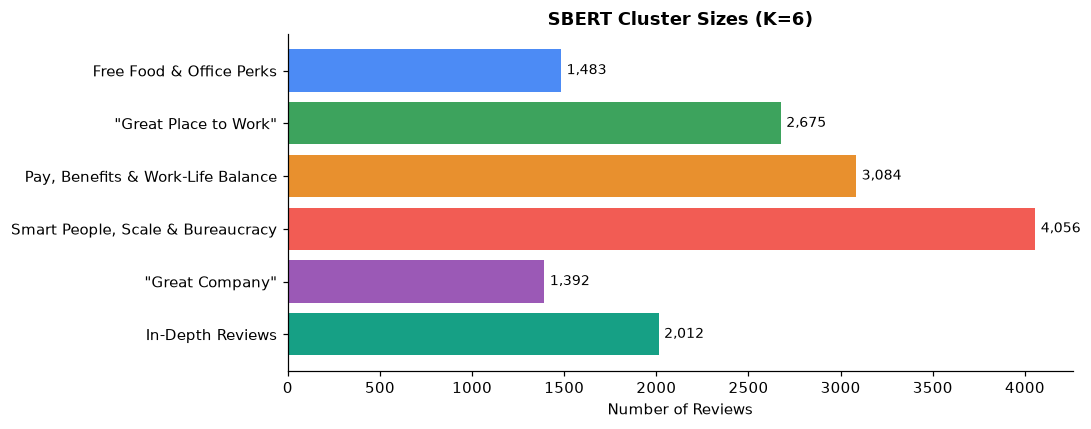

In [14]:
# ── Cluster size bar chart ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))

theme_labels = [CLUSTER_THEMES[c] for c in range(K)]
sizes  = [(df['cluster_sbert'] == c).sum() for c in range(K)]
colors_cl = ['#4C8BF5', '#3DA35D', '#E8902E', '#F25C54', '#9B59B6', '#16A085']

bars = ax.barh(theme_labels[::-1], sizes[::-1], color=colors_cl[::-1])
for bar, sz in zip(bars, sizes[::-1]):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
            f'{sz:,}', va='center', fontsize=9)

ax.set_xlabel('Number of Reviews')
ax.set_title('SBERT Cluster Sizes (K=6)', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('figs/cluster_sizes.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Business Insights

### Insight 1 — Senior Management Is Google's Weakest Area
Glassdoor reviewers can also rate six specific job areas. Comparing their averages shows where Google is strongest and weakest.

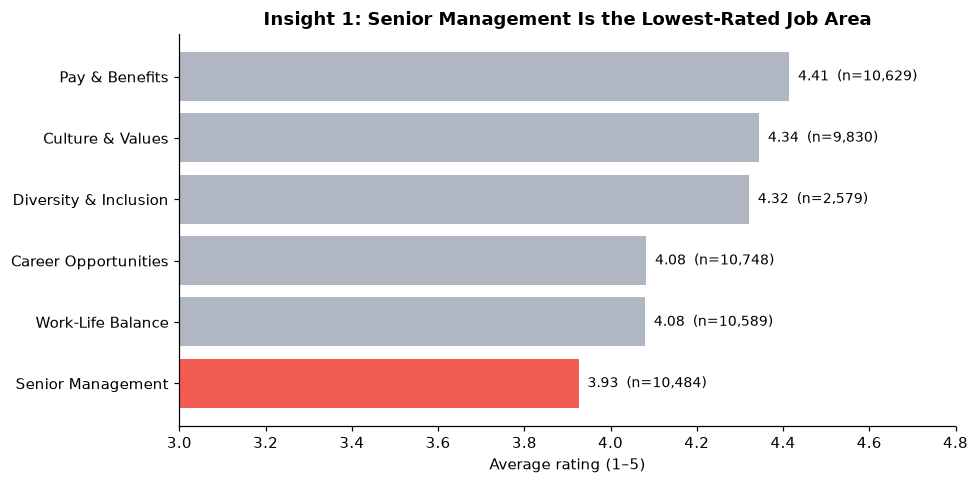

                 area  avg     n
       Pay & Benefits 4.41 10629
     Culture & Values 4.34  9830
Diversity & Inclusion 4.32  2579
 Career Opportunities 4.08 10748
    Work-Life Balance 4.08 10589
    Senior Management 3.93 10484

Overall rating (all reviews): 4.39


In [15]:
# ── Average rating for each of the six job areas ─────────────────────────────
SUBRATINGS = {
    'comp_benefits':       'Pay & Benefits',
    'culture_values':      'Culture & Values',
    'diversity_inclusion': 'Diversity & Inclusion',
    'work_life_balance':   'Work-Life Balance',
    'career_opp':          'Career Opportunities',
    'senior_mgmt':         'Senior Management',
}
sub = pd.DataFrame({
    'area':  list(SUBRATINGS.values()),
    'avg':   [df[c].mean() for c in SUBRATINGS],
    'n':     [df[c].notna().sum() for c in SUBRATINGS],
}).sort_values('avg')

fig, ax = plt.subplots(figsize=(9, 4.5))
colors_sub = ['#F25C54' if a == 'Senior Management' else '#B0B7C3' for a in sub['area']]
bars = ax.barh(sub['area'], sub['avg'], color=colors_sub)
for bar, (_, row) in zip(bars, sub.iterrows()):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
            f"{row['avg']:.2f}  (n={row['n']:,})", va='center', fontsize=9)

ax.set_xlim(3.0, 4.8)
ax.set_xlabel('Average rating (1–5)')
ax.set_title('Insight 1: Senior Management Is the Lowest-Rated Job Area', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('figs/insight1_subratings.png', dpi=150, bbox_inches='tight')
plt.show()

print(sub.sort_values('avg', ascending=False).round(2).to_string(index=False))
print(f"\nOverall rating (all reviews): {df['overall_rating'].mean():.2f}")

**Business Implication:** Employees rate pay and benefits highest (4.41) and senior management lowest (3.93) of the six job areas. Compensation is clearly not the problem; leadership is where employee sentiment has the most room to grow. (Diversity & Inclusion has far fewer ratings, about 2,600, because Glassdoor added that question later.)

### Insight 2 — The Management Gap Is Persistent, but Narrowing

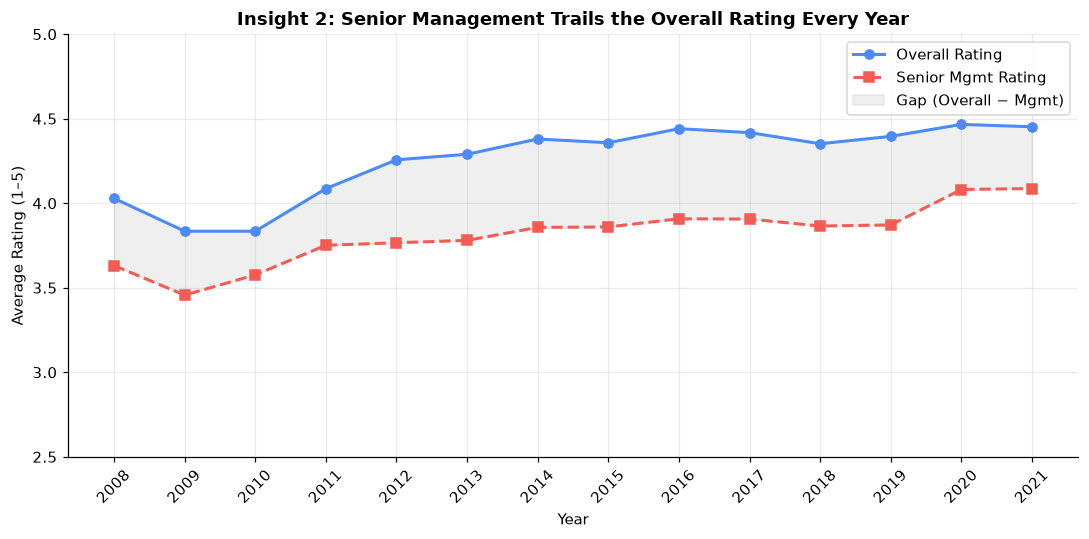

Rating gap (Overall − Senior Mgmt) by year:
review_year
2008    0.40
2009    0.38
2010    0.26
2011    0.34
2012    0.49
2013    0.51
2014    0.52
2015    0.50
2016    0.53
2017    0.51
2018    0.49
2019    0.52
2020    0.39
2021    0.37


In [16]:
# ── Average overall_rating and senior_mgmt rating by year ─────────────────────
yr_df = df.groupby('review_year').agg(
    avg_overall  = ('overall_rating', 'mean'),
    avg_mgmt     = ('senior_mgmt',    'mean'),
    n_reviews    = ('overall_rating', 'count')
).reset_index()

# Focus on years with ≥ 50 reviews for reliability
yr_df = yr_df[yr_df['n_reviews'] >= 50]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(yr_df['review_year'], yr_df['avg_overall'], 'o-',
        color='#4C8BF5', linewidth=2, markersize=6, label='Overall Rating')
ax.plot(yr_df['review_year'], yr_df['avg_mgmt'], 's--',
        color='#F25C54', linewidth=2, markersize=6, label='Senior Mgmt Rating')

ax.fill_between(yr_df['review_year'], yr_df['avg_mgmt'], yr_df['avg_overall'],
                alpha=0.12, color='gray', label='Gap (Overall − Mgmt)')

ax.set_xlabel('Year')
ax.set_ylabel('Average Rating (1–5)')
ax.set_title('Insight 2: Senior Management Trails the Overall Rating Every Year',
             fontweight='bold')
ax.set_ylim(2.5, 5.0)
ax.set_xticks(yr_df['review_year'])
ax.tick_params(axis='x', rotation=45)
ax.legend()
ax.grid(alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
fig.savefig('figs/insight2_mgmt_trend.png', dpi=150, bbox_inches='tight')
plt.show()

gap = yr_df.set_index('review_year')['avg_overall'] - yr_df.set_index('review_year')['avg_mgmt']
print('Rating gap (Overall − Senior Mgmt) by year:')
print(gap.round(2).to_string())

**Business Implication:** Senior management trailed the overall rating in every year from 2008 to 2021. The gap grew from roughly 0.3–0.4 points in 2008–2011 to about half a point from 2012 through 2019, then narrowed to 0.39 in 2020 and 0.37 in 2021 as management ratings rose. The weakness is long-standing rather than new, and the recent improvement is worth monitoring to see if it holds.

### Insight 3 — Perks Don't Make Up for the Work
Which themes carry the most dissatisfied employees? We compare the share of 1–2 star reviews in each theme, and the recommend rate among reviewers who gave an opinion (about a third chose "No opinion", so counting them as non-recommenders would understate every theme).

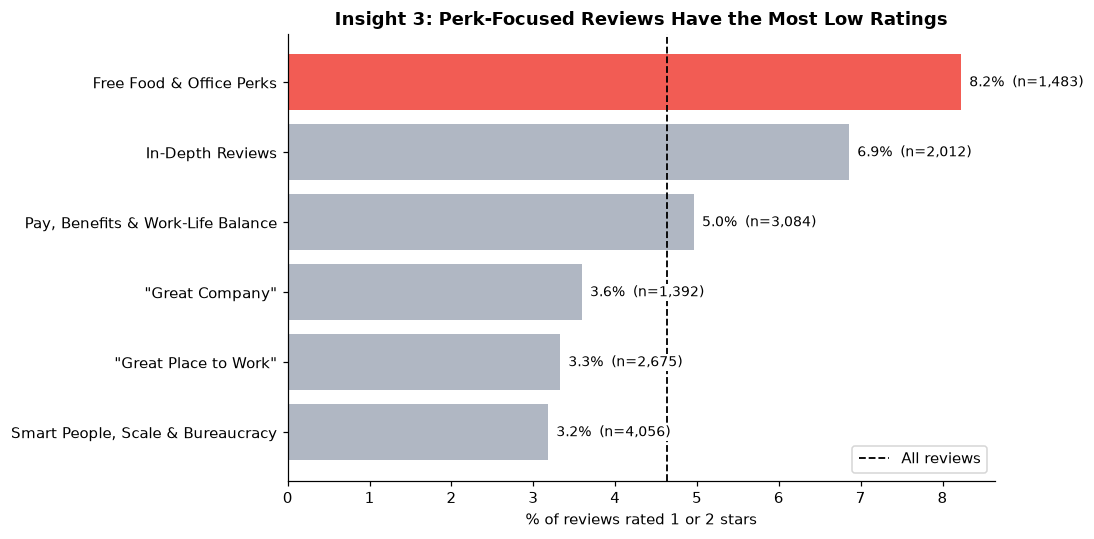

                            theme  low_share  recommend_rate  avg_rating    n
         Free Food & Office Perks      0.082           0.834       4.199 1483
                 In-Depth Reviews      0.069           0.891       4.356 2012
Pay, Benefits & Work-Life Balance      0.050           0.884       4.293 3084
                  "Great Company"      0.036           0.928       4.548 1392
            "Great Place to Work"      0.033           0.911       4.514 2675
Smart People, Scale & Bureaucracy      0.032           0.936       4.433 4056


In [17]:
# ── Share of 1–2 star reviews and recommend rate by theme ────────────────────
opinion = df['recommend'] != 'No opinion'
by_theme = (
    df.assign(low=(df['overall_rating'] <= 2).astype(int))
      .groupby('cluster_sbert')
      .agg(low_share=('low', 'mean'), avg_rating=('overall_rating', 'mean'), n=('low', 'count'))
)
by_theme['recommend_rate'] = (
    df[opinion].groupby('cluster_sbert')['recommend'].apply(lambda s: (s == 'Positive').mean())
)
by_theme['theme'] = by_theme.index.map(CLUSTER_THEMES)
by_theme = by_theme.sort_values('low_share')

fig, ax = plt.subplots(figsize=(10, 5))
palette = ['#F25C54' if t == 'Free Food & Office Perks' else '#B0B7C3' for t in by_theme['theme']]
bars = ax.barh(by_theme['theme'], by_theme['low_share'] * 100, color=palette)
for bar, (_, row) in zip(bars, by_theme.iterrows()):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f"{row['low_share']*100:.1f}%  (n={row['n']:,})", va='center', fontsize=9,
            bbox=dict(facecolor='white', edgecolor='none', pad=1), zorder=3)

ax.axvline((df['overall_rating'] <= 2).mean() * 100, color='black',
           linestyle='--', linewidth=1.2, label='All reviews', zorder=1)
ax.set_xlabel('% of reviews rated 1 or 2 stars')
ax.set_title('Insight 3: Perk-Focused Reviews Have the Most Low Ratings', fontweight='bold')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('figs/insight3_low_ratings_by_theme.png', dpi=150, bbox_inches='tight')
plt.show()

print(by_theme[['theme', 'low_share', 'recommend_rate', 'avg_rating', 'n']]
      .sort_values('low_share', ascending=False).round(3).to_string(index=False))

**Business Implication:** Reviews that focus on free food and office perks have the highest share of 1–2 star ratings (8.2%), more than twice the rate of the most positive themes (3.2–3.6%), and the lowest recommend rate (83%, against 88–94% for the other themes). Reviewers who mainly mention perks are often unhappy with the job itself, so perks alone do not drive satisfaction. Investment in the work experience and leadership will matter more than adding perks.

---
## 6. Representation Method Comparison — Summary Table

In [18]:
comparison = pd.DataFrame([
    {
        'Criterion': 'Representation type',
        'TF-IDF (LSA)': 'Sparse (bag-of-words weighted)',
        'SBERT': 'Dense (contextual transformer)'
    },
    {
        'Criterion': 'Vector dimensions',
        'TF-IDF (LSA)': '100 (post-SVD)',
        'SBERT': '384'
    },
    {
        'Criterion': f'Silhouette score (K={K})',
        'TF-IDF (LSA)': f'{sil_tfidf:.4f}',
        'SBERT': f'{sil_sbert:.4f}'
    },
    {
        'Criterion': 'Captures synonyms / paraphrases',
        'TF-IDF (LSA)': 'Partially (via LSA co-occurrence)',
        'SBERT': 'Yes (contextual meaning)'
    },
    {
        'Criterion': 'Interpretability',
        'TF-IDF (LSA)': 'High — features are words',
        'SBERT': 'Lower — dense latent space'
    },
    {
        'Criterion': 'Compute cost',
        'TF-IDF (LSA)': 'Low (seconds)',
        'SBERT': 'Moderate (minutes on CPU)'
    },
    {
        'Criterion': 'Best use case here',
        'TF-IDF (LSA)': 'Keyword extraction, cluster labeling',
        'SBERT': 'Semantic clustering, similarity search'
    },
])

print(comparison.to_string(index=False))
comparison

                      Criterion                         TF-IDF (LSA)                                  SBERT
            Representation type       Sparse (bag-of-words weighted)         Dense (contextual transformer)
              Vector dimensions                       100 (post-SVD)                                    384
         Silhouette score (K=6)                               0.0432                                 0.0412
Captures synonyms / paraphrases    Partially (via LSA co-occurrence)               Yes (contextual meaning)
               Interpretability            High — features are words             Lower — dense latent space
                   Compute cost                        Low (seconds)              Moderate (minutes on CPU)
             Best use case here Keyword extraction, cluster labeling Semantic clustering, similarity search


,Criterion,TF-IDF (LSA),SBERT
0,Representation type,Sparse (bag-of-words weighted),Dense (contextual transformer)
1,Vector dimensions,100 (post-SVD),384
2,Silhouette score (K=6),0.0432,0.0412
3,Captures synonyms / paraphrases,Partially (via LSA co-occurrence),Yes (contextual meaning)
4,Interpretability,High — features are words,Lower — dense latent space
5,Compute cost,Low (seconds),Moderate (minutes on CPU)
6,Best use case here,"Keyword extraction, cluster labeling","Semantic clustering, similarity search"


---
## 7. Save Outputs

In [19]:
# Save the final dataframe with cluster labels appended
df.to_csv('google_reviews_final.csv', index=False)
print('Saved google_reviews_final.csv')

# Save cluster summary
summary_df.to_csv('cluster_summary.csv', index=False)
print('Saved cluster_summary.csv')

# Save comparison table
comparison.to_csv('representation_comparison.csv', index=False)
print('Saved representation_comparison.csv')

print('\nAll figures saved to figs/')
print(os.listdir('figs/'))

Saved google_reviews_final.csv
Saved cluster_summary.csv
Saved representation_comparison.csv

All figures saved to figs/
['cluster_sizes.png', 'elbow_silhouette.png', 'insight1_subratings.png', 'insight2_mgmt_trend.png', 'insight3_low_ratings_by_theme.png', 'silhouette_comparison.png', 'similarity_comparison.png']


In [20]:
# ── Final reproducibility check ───────────────────────────────────────────────
import sklearn

print('=== Environment ===')
print(f'numpy              : {np.__version__}')
print(f'pandas             : {pd.__version__}')
print(f'scikit-learn       : {sklearn.__version__}')
try:
    import sentence_transformers
    print(f'sentence-transformers: {sentence_transformers.__version__}')
except ImportError:
    print('sentence-transformers: not installed (cached embeddings used)')
print(f'\nRandom seed used   : {SEED}')
print(f'Final dataset rows : {len(df):,}')
print(f'TF-IDF silhouette  : {sil_tfidf:.4f}')
print(f'SBERT  silhouette  : {sil_sbert:.4f}')



=== Environment ===
numpy              : 2.5.4
pandas             : 3.0.6
scikit-learn       : 1.9.1
sentence-transformers: not installed (cached embeddings used)

Random seed used   : 42
Final dataset rows : 14,702
TF-IDF silhouette  : 0.0432
SBERT  silhouette  : 0.0412


In [21]:
# Claude and chat gpt were used to assist with code, debugging, and analysis